# Ejercicio Ridge, Lasso y ElasticNet
Para este ejercicio vas a trabajar con datos de ventas de una empresa que fabrica muebles en España. Esta empresa es una Pyme que demanda conocer de antemano qué ingresos va a tener cada mes, ya que necesita pedir un anticipio a su entidad financiera de cara a poder abastecerse de materia prima al comenzar el mes. Como desconoce cuánto tiene que pedir, tira al alza y acaba pagando muchos intereses. El objetivo es reducir estos gastos.

En las bases de datos de la empresa constan todos los gastos en publicidad y ventas, para cada uno de los meses desde su fundación (hace más de 15 años).

Dado que los presupuestos de marketing se cierran al principio de cada mes, la empresa necesita un modelo predictivo que le anticipe las ventas que conseguirá a final de mes en función de los gastos que realizará en marketing.

Para ello tendrás que utilizar tanto modelos de regresión normales, como regularizados.

1. Carga los datos y realiza un pequeño análisis exploratorio. Mira a ver cómo se relaciona las ventas con el resto de variables.
2. Crea varios modelos y modifica los hiperparámetros necesarios para mejorar el performance del modelo.
3. Interpreta los resultados. Traduce a una fórmula tu mejor modelo (escribir la fórmula simplemente). ¿Cuánto cambian las ventas si aumentamos la inversión en radio un punto más? ¿Y si aumentamos la inversión en TV o periódicos?

## Import libraries 

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## Exploratory Data Analysis 

In [3]:
# Lectura datos, relación variables, mapas de correlación...

In [4]:
muebles = pd.read_csv("data/Advertising.csv")
muebles

,Unnamed: 0,TV,radio,newpaper,sales
0,0,230.1,37.8,6s9.2,22100.0
1,1,44.5,39.3,45.1,10400.0
2,2,17.2,45.9,69.3,9300.0
3,3,151.5,41.3,58.5,18500.0
4,4,180.8,10.8,58.4,12900.0
...,...,...,...,...,...
195,195,38.2,3.7,13.8,7600.0
196,196,94.2,4.9,8.1,9700.0
197,197,177.0,9.3,6.4,12800.0
198,198,283.6,42.0,66.2,25500.0


In [5]:
# Utiliza todas las celdas que necesites...

In [6]:
muebles.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  200 non-null    int64  
 1   TV          200 non-null    float64
 2   radio       200 non-null    float64
 3   newpaper    200 non-null    str    
 4   sales       200 non-null    float64
dtypes: float64(3), int64(1), str(1)
memory usage: 7.9 KB


In [7]:
muebles["newpaper"] = muebles["newpaper"].str.replace("s", "", regex=False)

In [8]:
muebles["newpaper"] = muebles["newpaper"].astype(float)

In [9]:
muebles.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  200 non-null    int64  
 1   TV          200 non-null    float64
 2   radio       200 non-null    float64
 3   newpaper    200 non-null    float64
 4   sales       200 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 7.9 KB


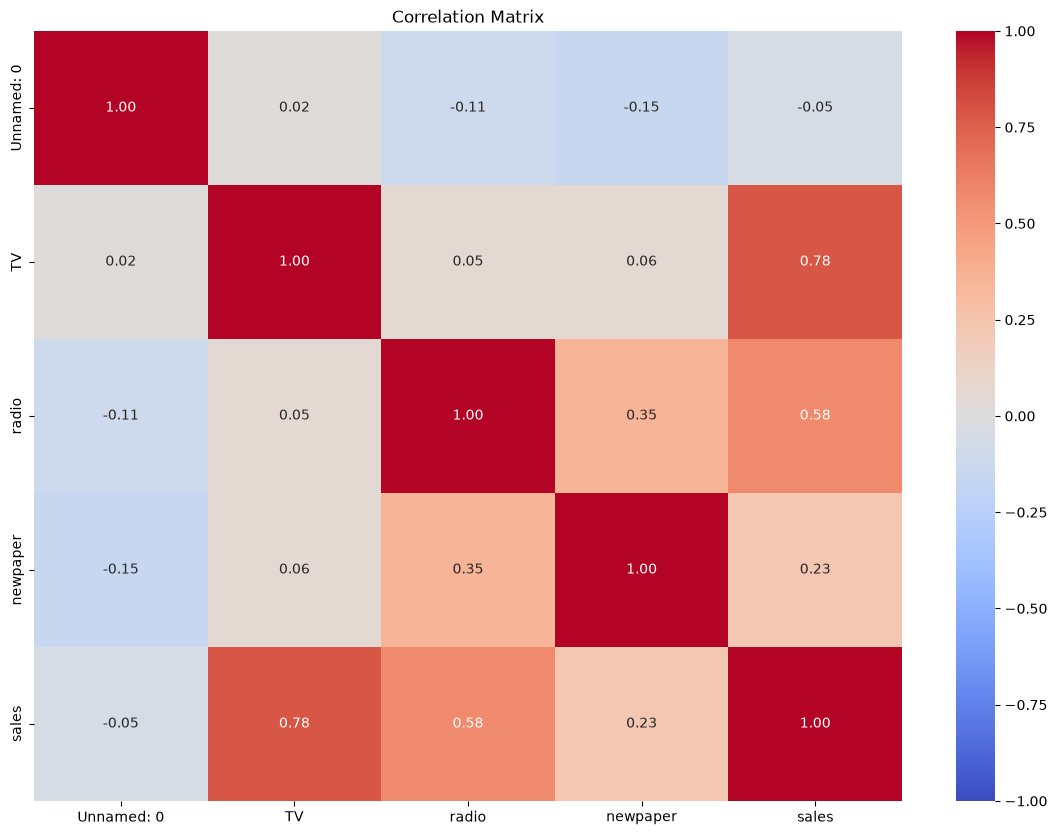

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 10))

sns.heatmap(muebles.corr(),
            annot=True,
            cmap="coolwarm",
            fmt=".2f",
            vmin=-1,
            vmax=1)

plt.title("Correlation Matrix")
plt.show()

## Modelado

In [11]:
# Manipulación datasets, entrenamiento, evaluación, nuevas iteraciones... Prueba modelos sin y con regularización.

In [12]:
# Utiliza todas las celdas que necesites...

In [13]:
X = muebles[["TV", "radio", "newpaper"]]
y = muebles["sales"]

In [14]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [15]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [16]:
model_train = LinearRegression()
model_train.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[ 44.73,189.2 , 2.76]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['TV','radio','newpaper']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2979
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,3


In [17]:
import numpy as np
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_absolute_percentage_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [18]:
predictions = model_train.predict(X_train)

print("MAE:", mean_absolute_error(y_train, predictions))
print("MAPE:", mean_absolute_percentage_error(y_train, predictions))
print("MSE:", mean_squared_error(y_train, predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_train, predictions)))
print("r2_score train:", model_train.score(X_train, y_train))

MAE: 1198.4678961500135
MAPE: 0.13651462127119013
MSE: 2705129.423081414
RMSE: 1644.7277656443373
r2_score train: 0.8957008271017817


In [19]:
predictions = model_train.predict(X_test)

print("MAE:", mean_absolute_error(y_test, predictions))
print("MAPE:", mean_absolute_percentage_error(y_test, predictions))
print("MSE:", mean_squared_error(y_test, predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, predictions)))
print("r2_score train:", model_train.score(X_test, y_test))

MAE: 1460.7567168117605
MAPE: 0.1519884660283123
MSE: 3174097.3539761053
RMSE: 1781.5996615334504
r2_score train: 0.899438024100912


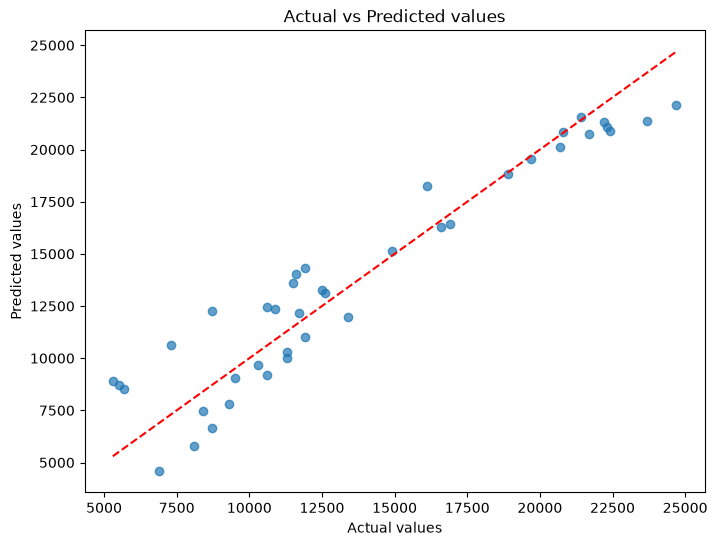

In [20]:
y_pred = model_train.predict(X_test)

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         color="red", linestyle="--")

plt.xlabel("Actual values")
plt.ylabel("Predicted values")
plt.title("Actual vs Predicted values")
plt.show()

### Modelos Polinómicos

In [21]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

In [22]:
poly = PolynomialFeatures(degree=2)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

In [23]:
model_poly = LinearRegression()
model_poly.fit(X_train_poly, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](10,)","[ 0. ,53.24,17.1 ,..., 0.13, 0.12, 0.03]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,4939
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,10
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,9
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](10,)","[324641.81, 53762.54, 29263.99,..., 67.97, 42.8 , 0. ]"


In [24]:
y_pred_poly = model_poly.predict(X_test_poly)

print("MAE:", mean_absolute_error(y_test, y_pred_poly))
print("MAPE:", mean_absolute_percentage_error(y_test, y_pred_poly))
print("MSE:", mean_squared_error(y_test, y_pred_poly))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_poly)))
print("R2 train:", model_poly.score(X_train_poly, y_train))
print("R2 test:", model_poly.score(X_test_poly, y_test))

MAE: 526.1794444044151
MAPE: 0.04893877124817329
MSE: 412910.2285379261
RMSE: 642.5809120553816
R2 train: 0.986104518792419
R2 test: 0.9869181490609596


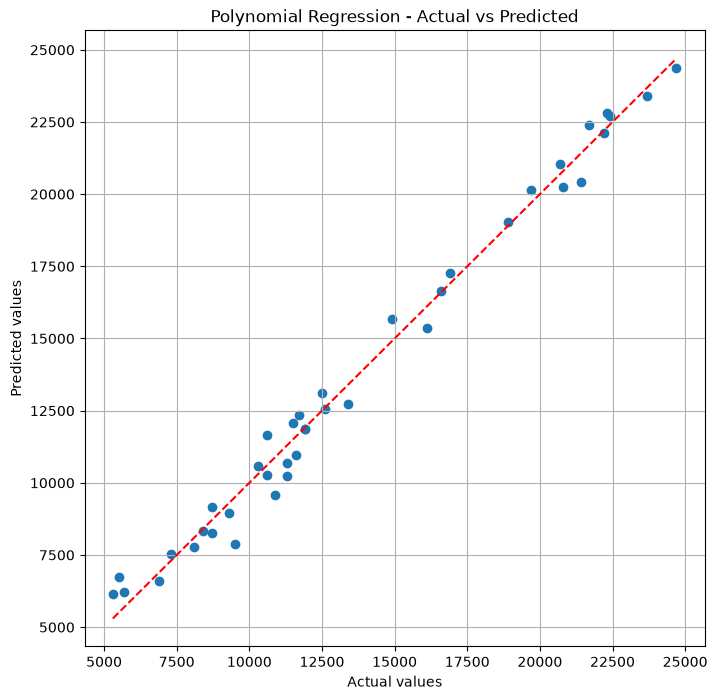

In [25]:
plt.figure(figsize=(8, 8))

plt.scatter(y_test, y_pred_poly)


plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         color="red", linestyle="--")

plt.xlabel("Actual values")
plt.ylabel("Predicted values")
plt.title("Polynomial Regression - Actual vs Predicted")

plt.grid()
plt.show()

In [26]:
from sklearn.linear_model import Ridge, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

In [27]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [28]:
from sklearn import metrics
baseline_error = metrics.mean_squared_error(y_test, model_poly.predict(X_test_poly))

In [29]:
n_alphas = 100
alphas = np.logspace(-4, 3, n_alphas) 

coef_ridge = []
err_ridge = []
baseline = []

for a in alphas:
    ridge = Ridge(alpha=a)
    ridge.fit(X_train_poly, y_train)
    
    coef_ridge.append(ridge.coef_)
    
    y_pred = ridge.predict(X_test_poly)
    ridge_error = metrics.mean_squared_error(y_pred, y_test)
    
    err_ridge.append(ridge_error)
    baseline.append(baseline_error)

In [30]:
min(err_ridge)

409434.5427239289

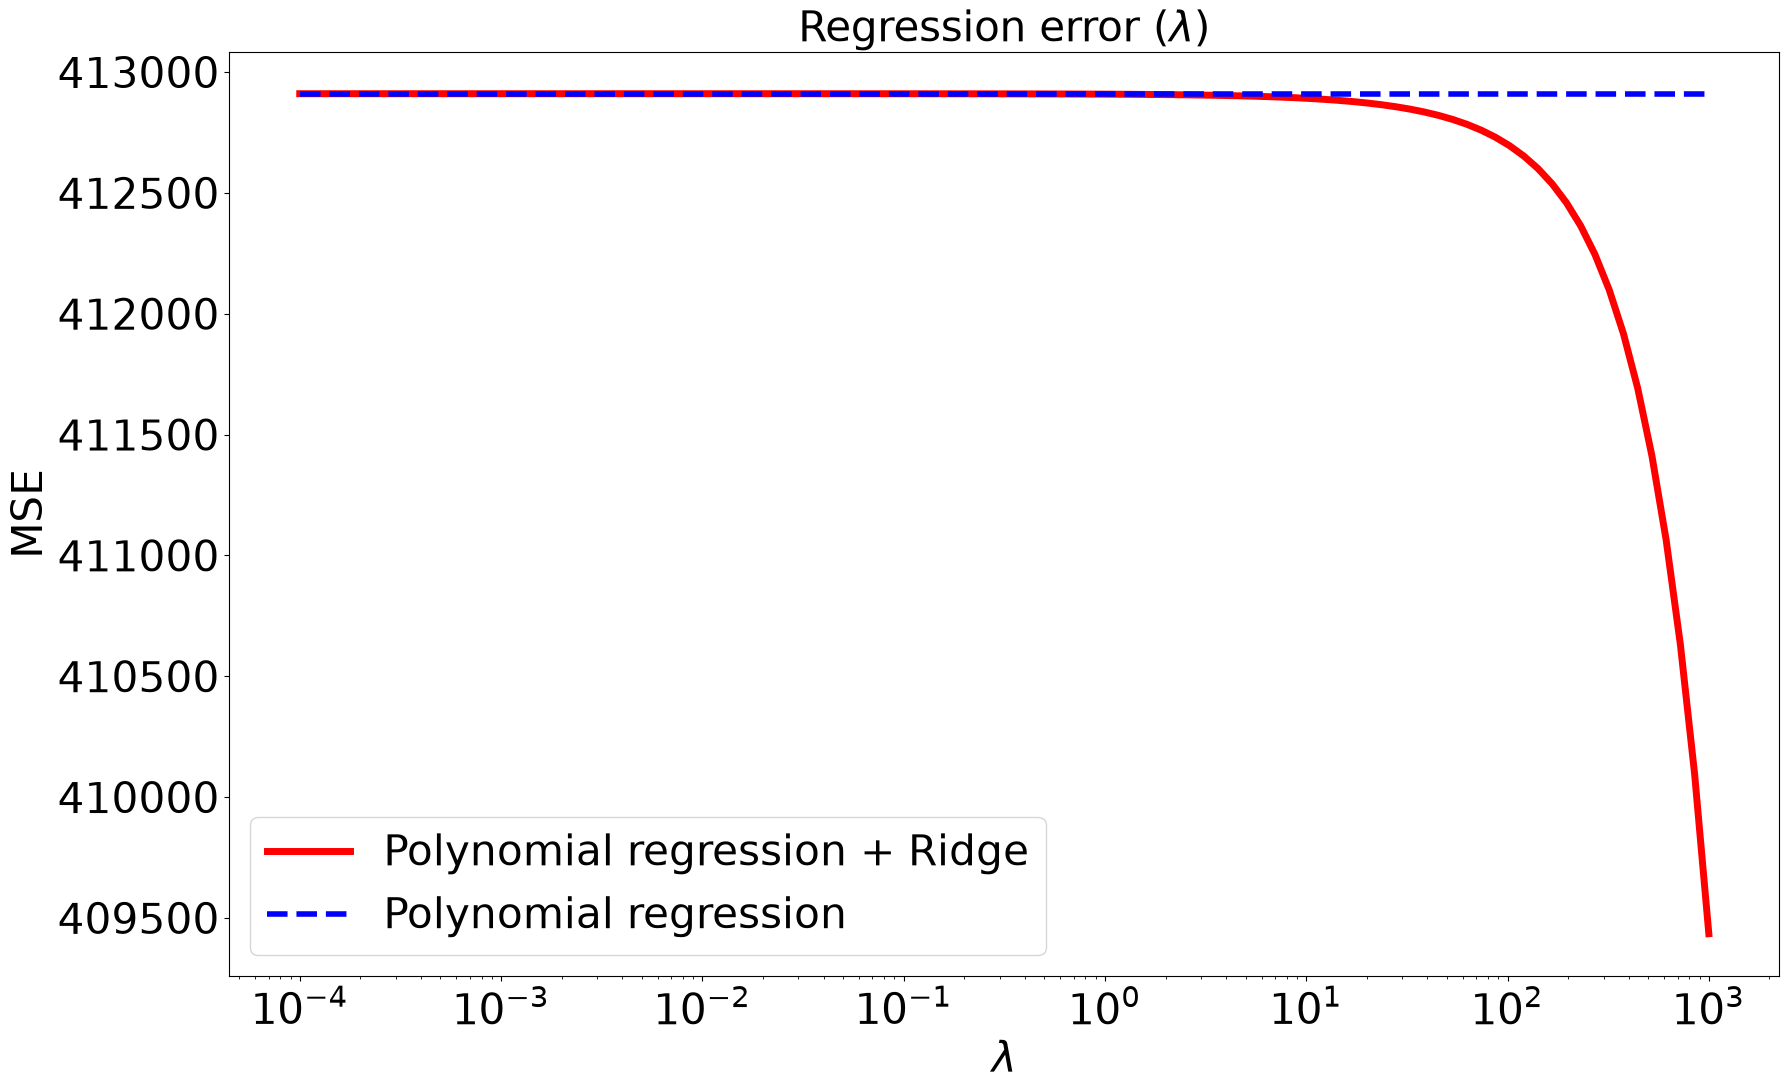

In [31]:
plt.figure(figsize=(20,12))
ax = plt.gca()

ax.plot(alphas, err_ridge, linewidth=5, color='red',
        label="Polynomial regression + Ridge")

ax.plot(alphas, baseline, linewidth=4, linestyle='--',
        color='blue', label='Polynomial regression')

ax.set_xscale('log')

plt.xlabel(r'$\lambda$', fontsize=30)
plt.xticks(fontsize=30)
plt.yticks(fontsize=30)
plt.ylabel('MSE', fontsize=30)
ax.legend(fontsize=30)
plt.title(r'Regression error ($\lambda$)', fontsize=30)
plt.show()

In [39]:
from sklearn.linear_model import ElasticNet
model_elastic = ElasticNet(alpha=100, l1_ratio=0.5 )
model_elastic.fit(X_train_poly, y_train)

y_pred_elastic = model_elastic.predict(X_test_poly)

In [40]:
from sklearn.linear_model import ElasticNet
from sklearn import metrics
import numpy as np

n_alphas = 100
alphas = np.logspace(-4, 3, n_alphas)

coef_elastic = []
err_elastic = []
baseline = []

baseline_error = metrics.mean_squared_error(y_test, model_poly.predict(X_test_poly))

for a in alphas:
    elastic = ElasticNet(alpha=a, l1_ratio=0.5, max_iter=10000)
    elastic.fit(X_train_poly, y_train)

    coef_elastic.append(elastic.coef_)

    y_pred_elastic = elastic.predict(X_test_poly)
    elastic_error = metrics.mean_squared_error(y_test, y_pred_elastic)

    err_elastic.append(elastic_error)
    baseline.append(baseline_error)

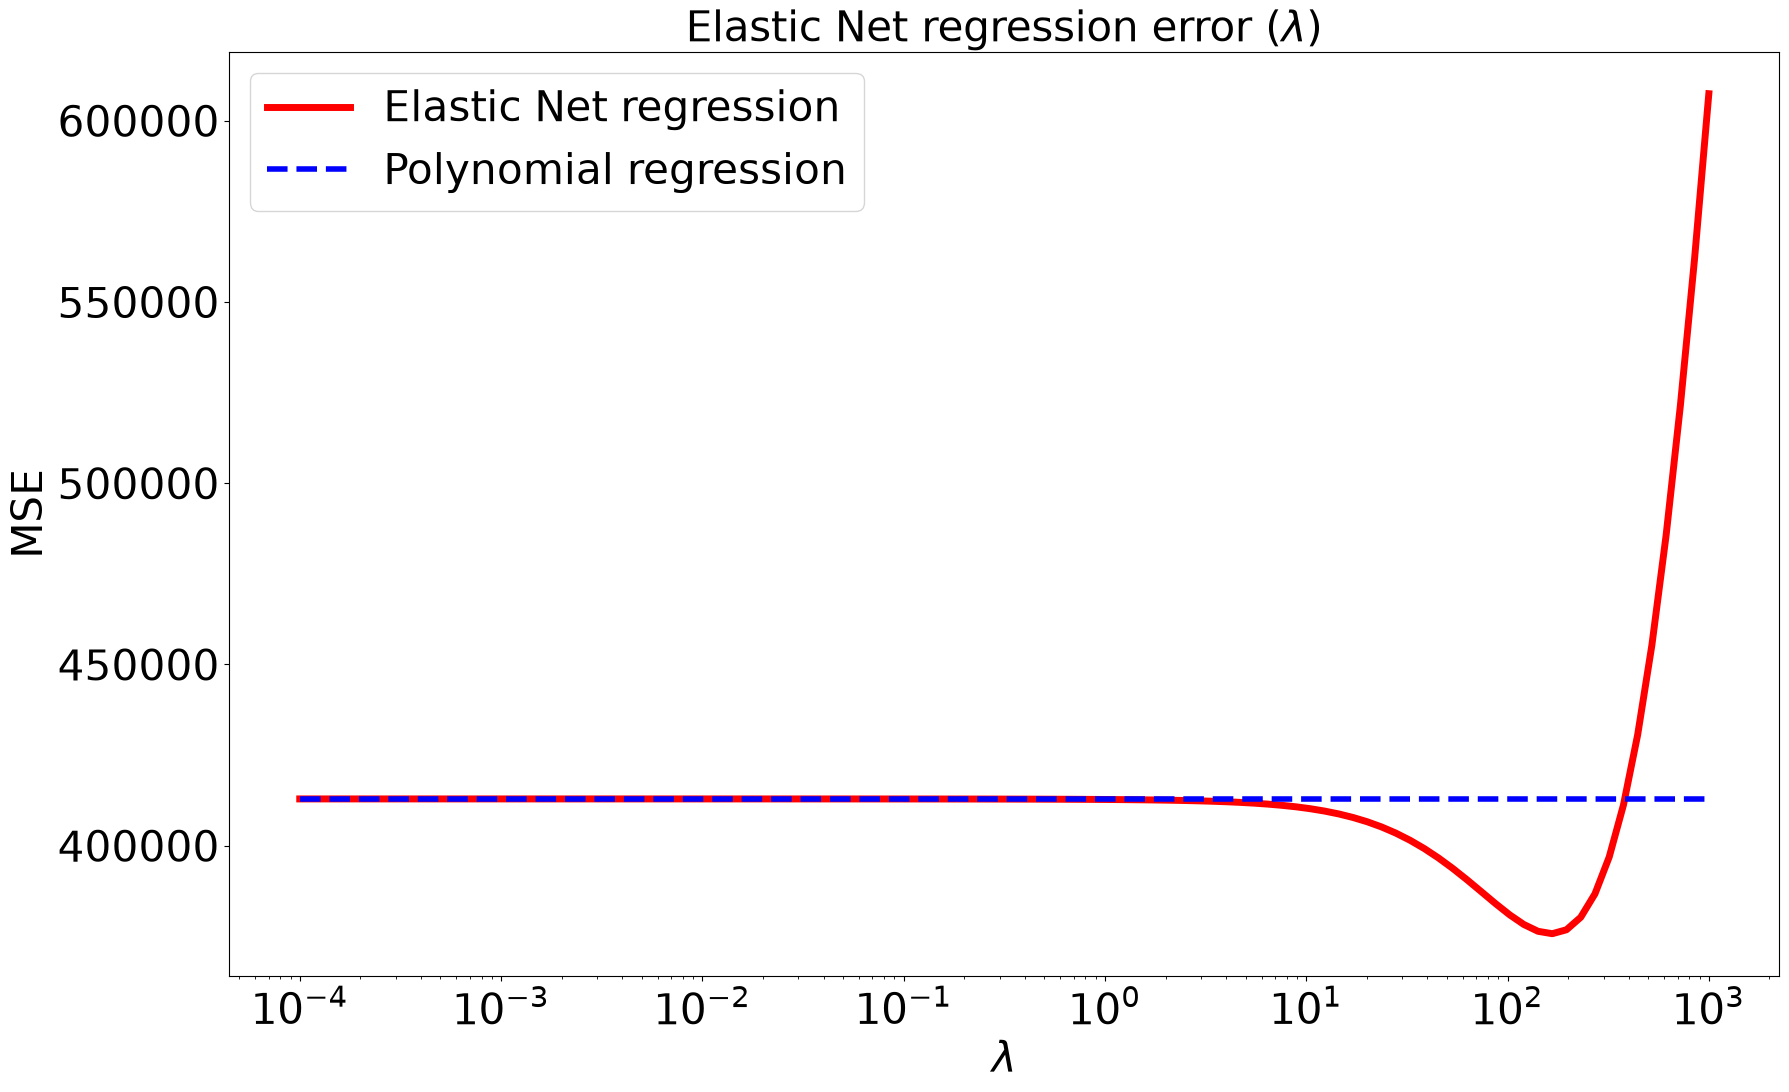

In [41]:
plt.figure(figsize=(20,12))
ax = plt.gca()

ax.plot(alphas, err_elastic, linewidth=5, color='red',
        label="Elastic Net regression")

ax.plot(alphas, baseline, linewidth=4, linestyle='--',
        color='blue', label='Polynomial regression')

ax.set_xscale('log')

plt.xlabel(r'$\lambda$', fontsize=30)
plt.xticks(fontsize=30)
plt.yticks(fontsize=30)
plt.ylabel('MSE', fontsize=30)
ax.legend(fontsize=30)
plt.title(r'Elastic Net regression error ($\lambda$)', fontsize=30)
plt.show()

In [33]:
y_pred_elastic = model_elastic.predict(X_test_poly)

print("MAE:", mean_absolute_error(y_test, y_pred_elastic))
print("MAPE:", mean_absolute_percentage_error(y_test, y_pred_elastic) * 100)
print("MSE:", mean_squared_error(y_test, y_pred_elastic))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_elastic)))
print("R2:", r2_score(y_test, y_pred_elastic))

MAE: 552.9974685205464
MAPE: 6.290985669697011
MSE: 607475.2526221847
RMSE: 779.4069877940437
R2: 0.9807539262660107


In [34]:
# Interpreta, resume y destaca los puntos importantes de los resultados.

In [35]:
# Utiliza todas las celdas que necesites...